# Step 1 — Data understanding

**Goal:** profile the raw data before any cleaning or modelling.

**Study (30–45 min):** class imbalance, meaning of each column.

**Think first (write in `decisions.md`):** Is a 7% default rate plausible? Which 3 variables will have the highest IV, and why? Write your guess before running code.

**Build:** shape, dtypes, missing-value table, summary statistics, target rate, histograms, boxplots, correlation heatmap. Flag odd values.

**Verify:** does the target rate match ~7%? Are flagged values real?

**Save:** `reports/tables/missing_values.csv` (required), plus `odd_values.csv` and EDA figures as supporting evidence.

**Scope note:** raw data is read-only. This notebook only describes — it does not impute, cap, delete rows, or split. No test set exists yet.

In [1]:
import sys
sys.path.insert(0, '..')  # allow importing src.*

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

In [2]:
# Load raw data. Kaggle adds an unnamed index column — drop it (schema fix only).
df = pd.read_csv(config.RAW_FILE)
dropped = [c for c in df.columns if c.startswith('Unnamed:')]
df = df.drop(columns=dropped)

print('Shape:', df.shape)
print('Unnamed index columns dropped:', dropped)
print('Rows scanned:', len(df), '(full file, no sampling)')

Shape: (150000, 11)
Unnamed index columns dropped: ['Unnamed: 0']
Rows scanned: 150000 (full file, no sampling)


In [3]:
# Dtypes + missing-value table
print('--- DTYPES ---')
print(df.dtypes.rename('dtype').to_string())

missing = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_missing': df.isna().sum(),
    'pct_missing': (df.isna().mean() * 100).round(2),
    'n_unique': df.nunique(dropna=True),
}).sort_values('n_missing', ascending=False)

config.TABLES.mkdir(parents=True, exist_ok=True)
config.FIGURES.mkdir(parents=True, exist_ok=True)
missing.to_csv(config.TABLES / 'missing_values.csv')
print('\n--- MISSING VALUES ---')
missing

--- DTYPES ---
SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64

--- MISSING VALUES ---


,dtype,n_missing,pct_missing,n_unique
MonthlyIncome,float64,29731,19.82,13594
NumberOfDependents,float64,3924,2.62,13
SeriousDlqin2yrs,int64,0,0.00,2
age,int64,0,0.00,86
RevolvingUtilizationOfUnsecuredLines,float64,0,0.00,125728
DebtRatio,float64,0,0.00,114194
NumberOfTime30-59DaysPastDueNotWorse,int64,0,0.00,16
NumberOfOpenCreditLinesAndLoans,int64,0,0.00,58
NumberOfTimes90DaysLate,int64,0,0.00,19
NumberRealEstateLoansOrLines,int64,0,0.00,28


In [4]:
# Summary statistics — compare mean/SD with median/IQR to see outlier influence
stats = df.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T.round(2)
stats

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
SeriousDlqin2yrs,150000.0,0.07,0.25,0.0,0.0,0.0,0.00,0.00,0.00,1.0,1.00,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.05,249.76,0.0,0.0,0.0,0.03,0.15,0.56,1.0,1.09,50708.0
age,150000.0,52.30,14.77,0.0,24.0,29.0,41.00,52.00,63.00,78.0,87.00,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.42,4.19,0.0,0.0,0.0,0.00,0.00,0.00,2.0,4.00,98.0
DebtRatio,150000.0,353.01,2037.82,0.0,0.0,0.0,0.18,0.37,0.87,2449.0,4979.04,329664.0
MonthlyIncome,120269.0,6670.22,14384.67,0.0,0.0,1300.0,3400.00,5400.00,8249.00,14587.6,25000.00,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.45,5.15,0.0,0.0,2.0,5.00,8.00,11.00,18.0,24.00,58.0
NumberOfTimes90DaysLate,150000.0,0.27,4.17,0.0,0.0,0.0,0.00,0.00,0.00,1.0,3.00,98.0
NumberRealEstateLoansOrLines,150000.0,1.02,1.13,0.0,0.0,0.0,0.00,1.00,2.00,3.0,4.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.24,4.16,0.0,0.0,0.0,0.00,0.00,0.00,1.0,2.00,98.0


In [5]:
# Target rate — is ~7% default plausible?
n_default = int(df[config.TARGET].sum())
pct_default = df[config.TARGET].mean() * 100
print(f'Defaults: {n_default:,} of {len(df):,} = {pct_default:.2f}%')
print('Imbalance ratio ~ 1 :', round((len(df) - n_default) / n_default, 1))
print('\nClass counts:')
print(df[config.TARGET].value_counts().sort_index().to_string())

Defaults: 10,026 of 150,000 = 6.68%
Imbalance ratio ~ 1 : 14.0

Class counts:
SeriousDlqin2yrs
0    139974
1     10026


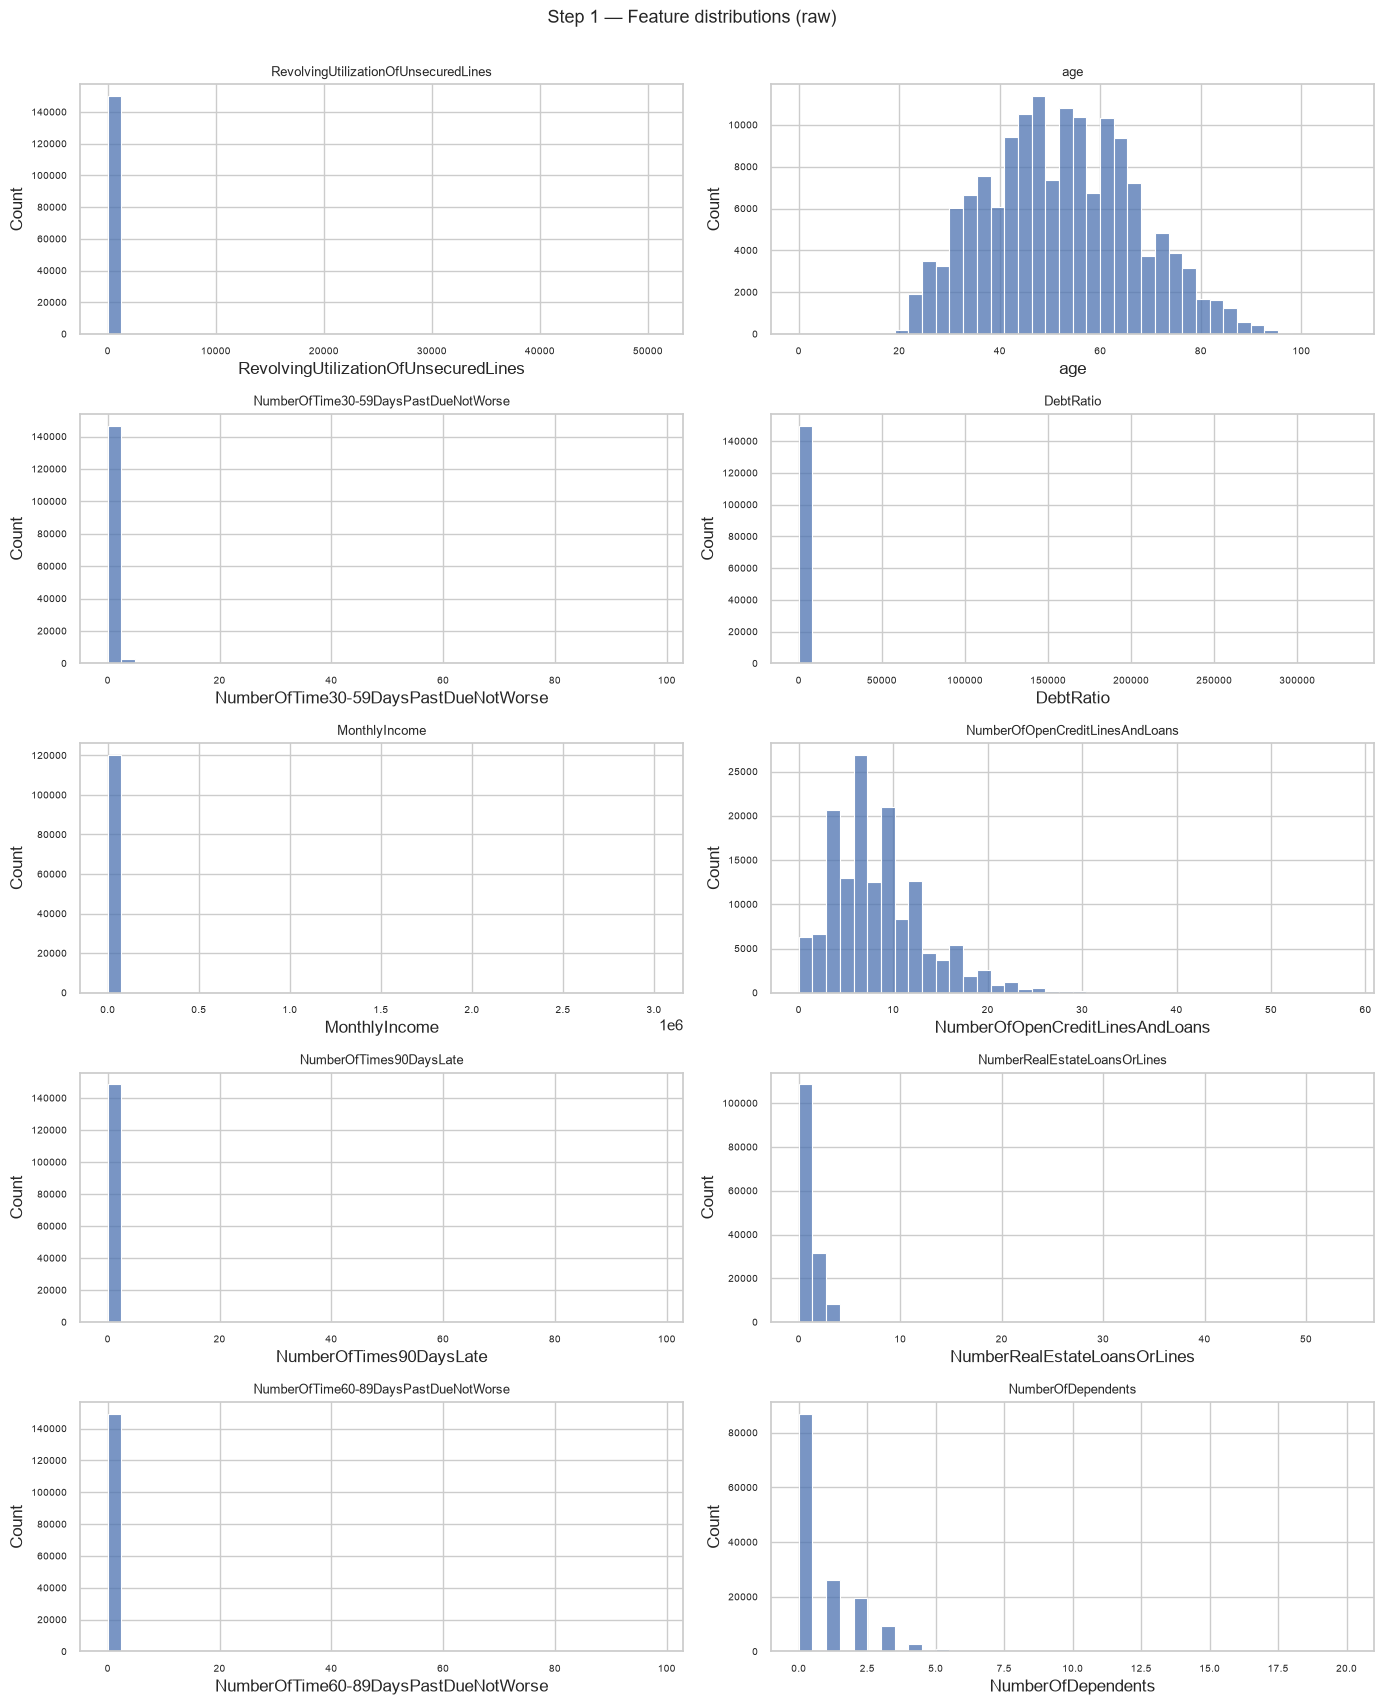

In [6]:
# Histograms — raw distributions, untransformed
features = [c for c in df.columns if c != config.TARGET]
rows = (len(features) + 1) // 2
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.4 * rows))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col].dropna(), bins=40, ax=ax)
    ax.set_title(col, fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(features):]:
    ax.set_visible(False)
fig.suptitle('Step 1 — Feature distributions (raw)', y=1.002, fontsize=13)
plt.tight_layout()
fig.savefig(config.FIGURES / 'eda_histograms.png', dpi=110, bbox_inches='tight')
plt.show()

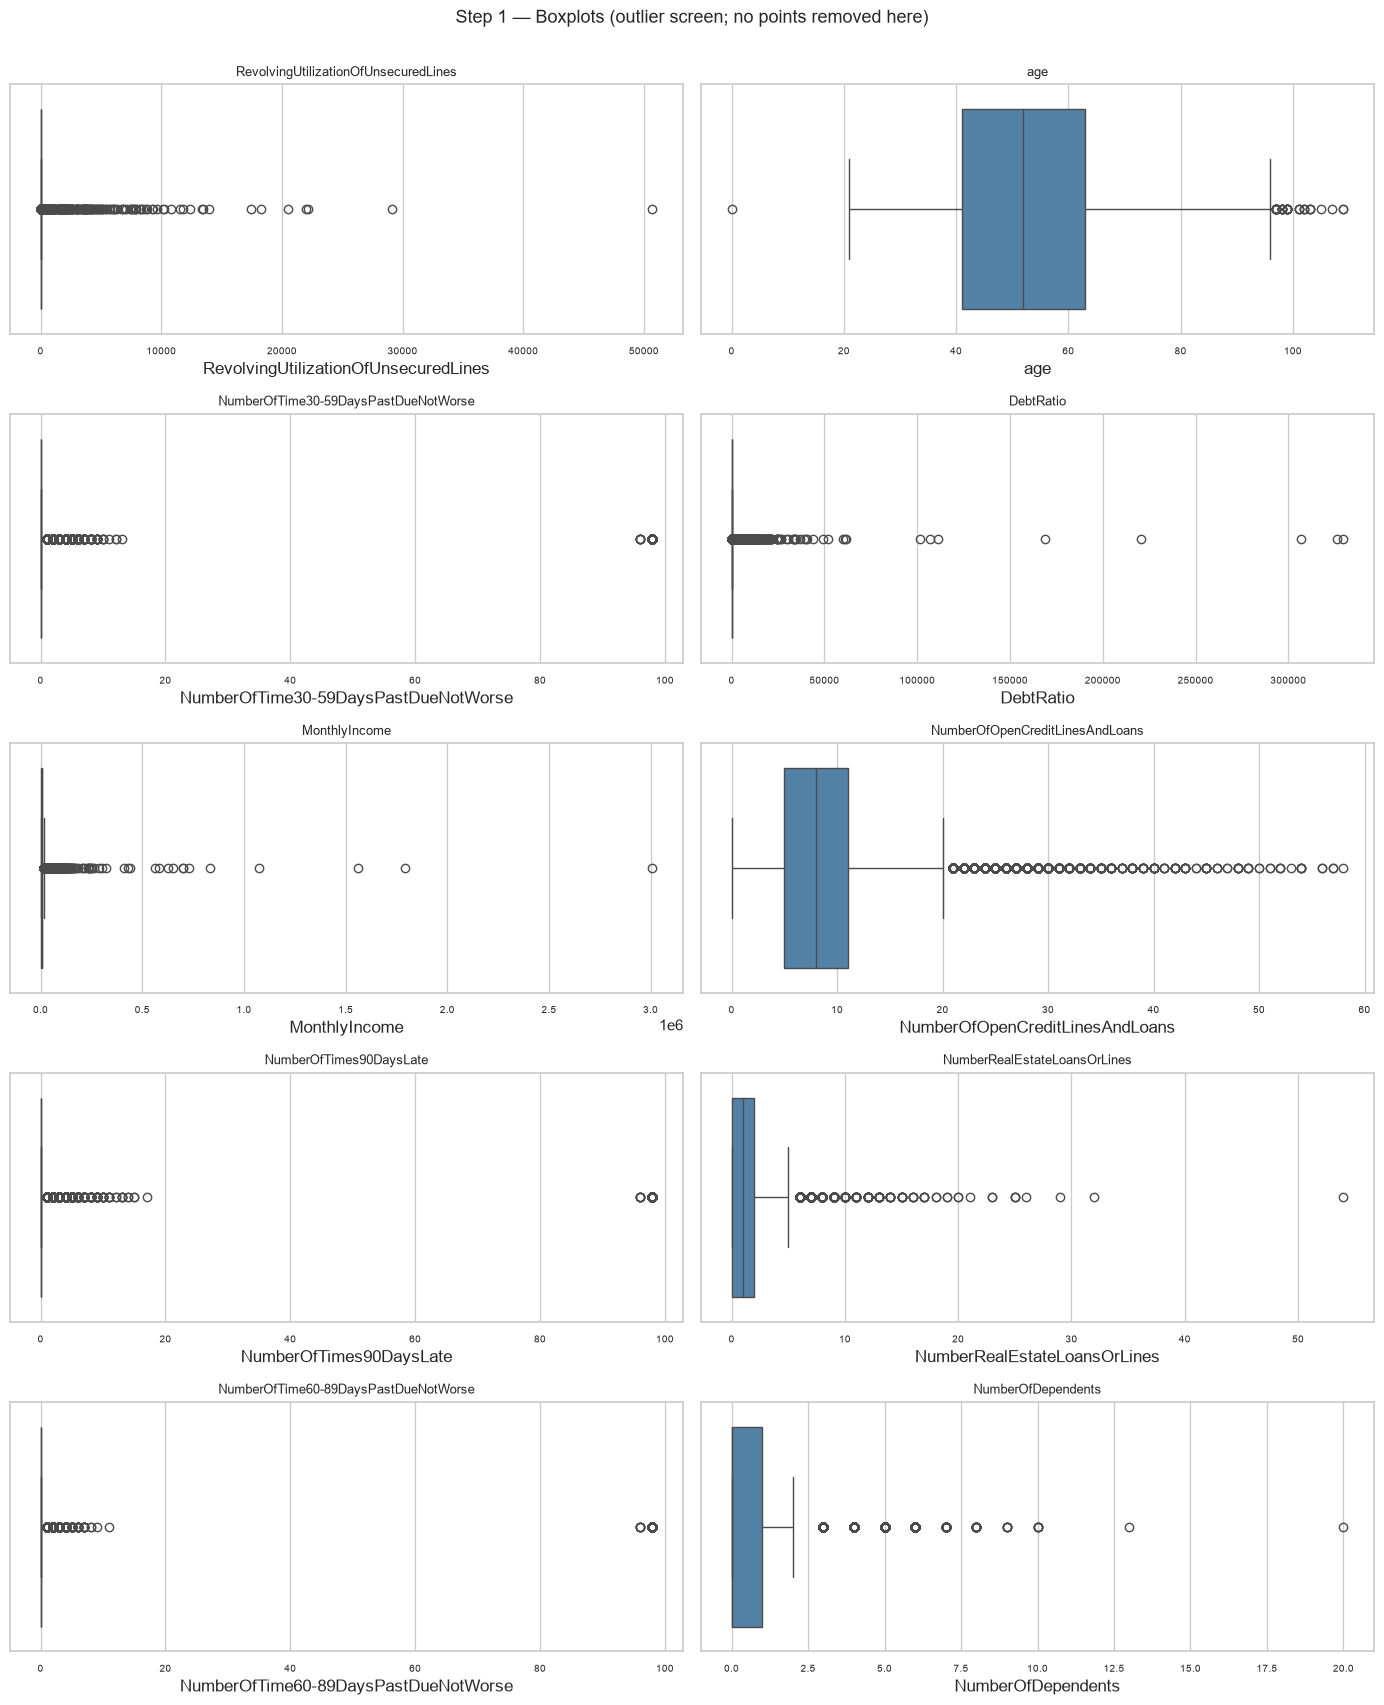

In [7]:
# Boxplots — outlier screen only. FLAGS ARE NOT DELETION RULES.
fig, axes = plt.subplots(rows, 2, figsize=(14, 3.4 * rows))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(x=df[col].dropna(), ax=ax, color='steelblue')
    ax.set_title(col, fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(features):]:
    ax.set_visible(False)
fig.suptitle('Step 1 — Boxplots (outlier screen; no points removed here)', y=1.002, fontsize=13)
plt.tight_layout()
fig.savefig(config.FIGURES / 'eda_boxplots.png', dpi=110, bbox_inches='tight')
plt.show()

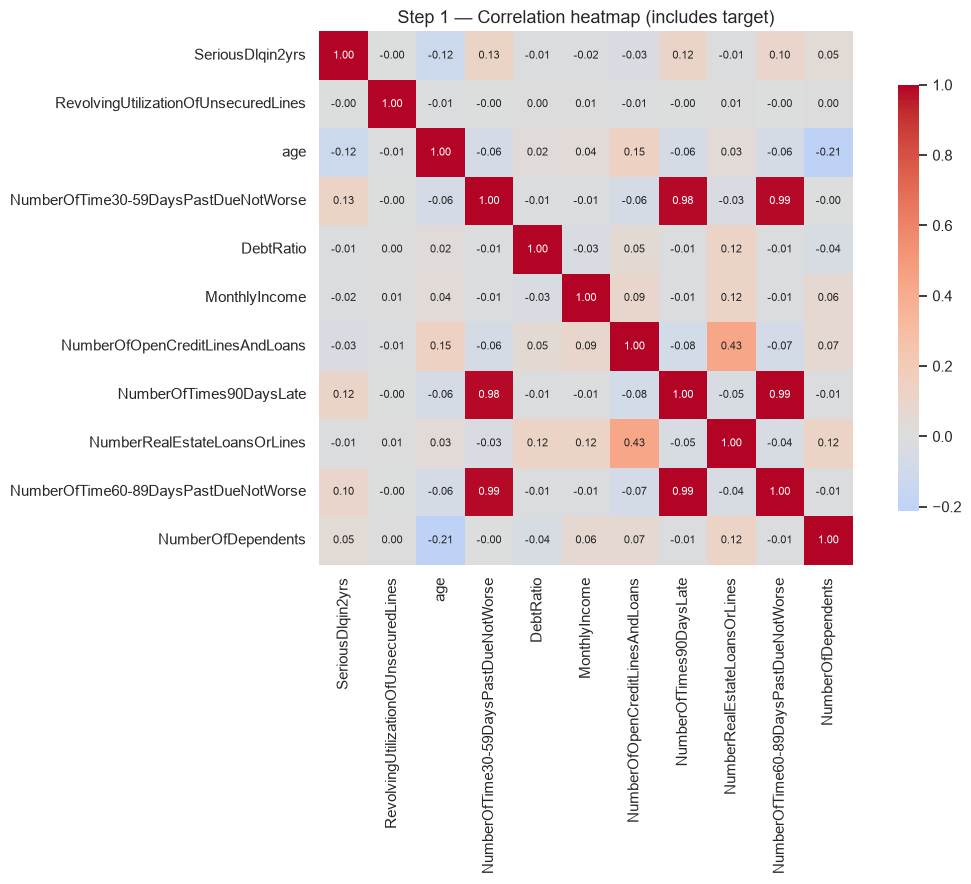

Correlation with target, strongest first:
NumberOfTime30-59DaysPastDueNotWorse    0.126
NumberOfTimes90DaysLate                 0.117
age                                     0.115
NumberOfTime60-89DaysPastDueNotWorse    0.102
NumberOfDependents                      0.046
NumberOfOpenCreditLinesAndLoans         0.030
MonthlyIncome                           0.020
DebtRatio                               0.008
NumberRealEstateLoansOrLines            0.007
RevolvingUtilizationOfUnsecuredLines    0.002


In [8]:
# Correlation heatmap — includes the target for a first signal check
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True,
            ax=ax, annot_kws={'size': 8}, cbar_kws={'shrink': .8})
ax.set_title('Step 1 — Correlation heatmap (includes target)', fontsize=13)
plt.tight_layout()
fig.savefig(config.FIGURES / 'eda_correlation.png', dpi=110, bbox_inches='tight')
plt.show()

print('Correlation with target, strongest first:')
print(corr[config.TARGET].drop(config.TARGET).abs().sort_values(ascending=False).round(3).to_string())

In [9]:
# Flag odd values for Step 2. These are diagnostics, not cleaning rules.
flags = []
for col in config.PAST_DUE_COLS:
    flags.append({'check': f'{col} in {config.SPECIAL_PAST_DUE_CODES}',
                  'n': int(df[col].isin(config.SPECIAL_PAST_DUE_CODES).sum())})
flags += [
    {'check': 'age == 0', 'n': int((df['age'] == 0).sum())},
    {'check': 'age > 100', 'n': int((df['age'] > 100).sum())},
    {'check': 'RevolvingUtilization > 1', 'n': int((df['RevolvingUtilizationOfUnsecuredLines'] > 1).sum())},
    {'check': 'DebtRatio > 10', 'n': int((df['DebtRatio'] > 10).sum())},
    {'check': 'any negative value across features', 'n': int((df[features] < 0).any(axis=1).sum())},
]
flags_df = pd.DataFrame(flags)
flags_df['pct_of_rows'] = (flags_df['n'] / len(df) * 100).round(3)
flags_df.to_csv(config.TABLES / 'odd_values.csv', index=False)
flags_df

,check,n,pct_of_rows
0,"NumberOfTime30-59DaysPastDueNotWorse in (96, 98)",269,0.179
1,"NumberOfTime60-89DaysPastDueNotWorse in (96, 98)",269,0.179
2,"NumberOfTimes90DaysLate in (96, 98)",269,0.179
3,age == 0,1,0.001
4,age > 100,13,0.009
5,RevolvingUtilization > 1,3321,2.214
6,DebtRatio > 10,28877,19.251
7,any negative value across features,0,0.000


## Findings (one sentence per chart)

- **Target rate:** 10,026 of 150,000 borrowers defaulted (6.68%, ~1:14 imbalance) — plausible and close to the ~7% expectation, but it means accuracy is a useless metric and we need AUC/Gini/KS later.
- **Missing values:** only `MonthlyIncome` (29,731 = 19.82%) and `NumberOfDependents` (3,924 = 2.62%) are incomplete; all other columns are fully populated.
- **Histograms:** every count variable is zero-inflated with a long right tail, while the two ratio columns have extreme tails (max 50,708 and 329,664) even though the medians are only 0.15 and 0.37.
- **Boxplots:** the extreme ratio and income values (max 3.0M vs median 5,400) dominate the scale and make raw boxplots hard to read — a flag for capping/binning in Step 2, **not** a deletion rule.
- **Correlation heatmap:** the three past-due counts and `age` have the strongest linear association with default (r = 0.126, 0.117, 0.115, 0.102); compare this with the Day 0 guess in `decisions.md`. Correlation is only a first signal — IV comes in Step 4.
- **Odd values:** 269 rows (0.18%) carry the 96/98 special code in all three past-due fields, 1 row has age 0, 13 rows have age > 100, 3,321 rows (2.21%) have utilization > 1, and 28,877 rows (19.25%) have DebtRatio > 10; no negative values were found.

**Step 2 decisions to make (not made here):** median-impute income; choose 0 vs median for dependents; treat 96/98 as an invalid/special code; fix age 0; set cap levels for the two ratios. Justify each choice in `decisions.md`.

**Provenance:** raw file treated as read-only; all 150,000 rows scanned, no sampling, imputation, or row deletion. Bounded EDA reporting followed the K-Dense Scientific Agent Skills exploratory-data-analysis guidance (Kassis et al., 2026, https://doi.org/10.48550/arXiv.2609.00065).